# Aula 8 — Prática de Filogenética e Evolução Molecular

**Introdução à Bioinformática — PPGED/IME**

## A pergunta da prática

> **Quando e por onde o vírus Zika chegou às Américas?**

Entre 2015 e 2016 houve uma grande epidemia de Zika nas Américas. A pergunta "*desde quando o vírus circulava e qual foi a rota de entrada?*" foi respondida **lendo e comparando os genomas do vírus** — uma aplicação clássica de **epidemiologia molecular / genômica**.

Vamos refazer essa análise em escala de sala de aula, com **34 genomas completos** do vírus Zika depositados no **GenBank** (o mesmo conjunto público usado no tutorial do projeto Nextstrain), usando apenas ferramentas **gratuitas e de código aberto**.

## O que você vai fazer

| Bloco | O que faz | Ferramenta |
|---|---|---|
| A | Carregar e inspecionar as sequências | Biopython |
| B | Alinhar os genomas (MSA) | MAFFT |
| C | Escolher o modelo evolutivo e construir a árvore de máxima verossimilhança | IQ-TREE |
| D | Ler e enraizar a árvore; interpretar o suporte (bootstrap) | Biopython |
| E | Datar a árvore (relógio molecular) e estimar quando o ancestral comum existiu | TreeTime |

> **Você não precisa saber programar.** Em cada célula de código basta clicar no ▶ e **ler o que sai**. O comentário acima de cada bloco explica o que vai acontecer e **o que observar**. O objetivo é *executar, observar e interpretar*.

## Antes de começar — leia 1 minuto

Este notebook funciona em duas situações:

1. **Google Colab** (recomendado, nada a instalar na sua máquina): abra [colab.research.google.com](https://colab.research.google.com), *Arquivo → Fazer upload de notebook*, e envie este `.ipynb`. A primeira célula instala tudo.
2. **Sua máquina**, se você já tiver um ambiente Conda da disciplina.

As ferramentas que vamos instalar:

- **MAFFT** — alinhador múltiplo de sequências (*Multiple Alignment using Fast Fourier Transform*). Alinha os 34 genomas para que cada coluna represente a mesma posição evolutiva.
- **IQ-TREE 2** — programa de inferência de árvores por **máxima verossimilhança**, com seleção automática de modelo (ModelFinder) e suporte por **bootstrap ultrarrápido**.
- **Biopython** — biblioteca Python para ler/escrever sequências e manipular árvores.
- **TreeTime** — ajusta um **relógio molecular** e transforma a árvore (em substituições) numa árvore **no tempo** (em anos).
- **pyMSAviz** — desenha o alinhamento para inspeção visual.

In [1]:
# === Célula de instalação (rode UMA vez; ~1-2 min no Colab) ===
# No Colab isto instala MAFFT (via apt), o binário do IQ-TREE 2 e os pacotes Python.
import os, sys, shutil, subprocess, platform

def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=False)

IN_COLAB = "google.colab" in sys.modules

# 1) MAFFT
if shutil.which("mafft") is None:
    if IN_COLAB or shutil.which("apt-get"):
        sh("apt-get -qq update && apt-get -qq install -y mafft >/dev/null")
    else:
        print("Instale o MAFFT pelo seu gerenciador (conda install -c bioconda mafft).")

# 2) Pacotes Python
sh(f"{sys.executable} -m pip install -q biopython phylo-treetime pymsaviz pandas matplotlib")

# 3) IQ-TREE 2 (binário oficial, Linux). Guardamos o caminho em IQTREE.
IQTREE = shutil.which("iqtree2") or shutil.which("iqtree")
if IQTREE is None and (IN_COLAB or platform.system() == "Linux"):
    url = ("https://github.com/iqtree/iqtree2/releases/download/v2.3.6/"
           "iqtree-2.3.6-Linux-intel.tar.gz")
    sh(f"wget -q {url} -O iqtree.tar.gz && tar xzf iqtree.tar.gz")
    IQTREE = os.path.abspath("iqtree-2.3.6-Linux-intel/bin/iqtree2")
print("\nMAFFT :", shutil.which("mafft"))
print("IQ-TREE:", IQTREE)

$ /usr/bin/python3 -m pip install -q biopython phylo-treetime pymsaviz pandas matplotlib



MAFFT : /usr/bin/mafft
IQ-TREE: /usr/local/bin/iqtree2


In [2]:
# Confirma que tudo respondeu
import shutil, subprocess, sys
assert shutil.which("mafft"), "MAFFT não encontrado"
assert IQTREE, "IQ-TREE não encontrado"
print(subprocess.run(["mafft", "--version"], capture_output=True, text=True).stderr.strip())
print(subprocess.run([IQTREE, "--version"], capture_output=True, text=True).stdout.splitlines()[0])
import Bio, pymsaviz
from importlib.metadata import version
print("Biopython", Bio.__version__, "| TreeTime", version("phylo-treetime"), "| pyMSAviz", pymsaviz.__version__)

v7.505 (2022/Apr/10)
IQ-TREE multicore version 2.3.6 for Linux x86 64-bit built Aug  1 2024


Biopython 1.88 | TreeTime 0.12.1 | pyMSAviz 0.5.0


---
# Bloco A — Os dados: 34 genomas do vírus Zika (10 min)

Vamos baixar dois arquivos públicos do tutorial do Nextstrain:

- `sequences.fasta` — os **34 genomas completos** do Zika em formato **FASTA** (texto: um cabeçalho `>nome` seguido da sequência de nucleotídeos A/C/G/T).
- `metadata.tsv` — uma tabela com, para cada genoma, o **nome da cepa**, o **número de acesso no GenBank**, a **data de coleta** e o **local** (país/região).

> **Por que precisamos das datas e dos locais?** Porque a filogenética sozinha diz *quem é parente de quem*. São as **datas** que permitem calibrar o relógio molecular (Bloco E) e os **locais** que permitem ler a árvore como uma história de dispersão geográfica.

In [3]:
# Baixa os dados públicos (GitHub do tutorial Nextstrain/zika).
import os, urllib.request

BASE = "https://raw.githubusercontent.com/nextstrain/zika-tutorial/master/data/"
for nome in ["sequences.fasta", "metadata.tsv"]:
    if not os.path.exists(nome):
        urllib.request.urlretrieve(BASE + nome, nome)
        print("baixado:", nome)
    else:
        print("já existe:", nome)

# Se o download for bloqueado pela rede da sua instituição, baixe os dois arquivos
# manualmente pelo navegador (mesma URL acima) e arraste-os para o painel de
# arquivos do Colab (ícone de pasta à esquerda). Teste isso na véspera.

já existe: sequences.fasta
já existe: metadata.tsv


In [4]:
# Lê o FASTA com Biopython e mostra um resumo
from Bio import SeqIO

registros = list(SeqIO.parse("sequences.fasta", "fasta"))
print("Número de genomas:", len(registros))

comprimentos = [len(r.seq) for r in registros]
print("Comprimento (nt): mínimo = %d | máximo = %d" % (min(comprimentos), max(comprimentos)))
print("\nPrimeiros 3 genomas:")
for r in registros[:3]:
    print(f"  {r.id:35s} {len(r.seq):6d} nt   início: {str(r.seq[:40])}...")

Número de genomas: 34
Comprimento (nt): mínimo = 9092 | máximo = 10812

Primeiros 3 genomas:
  PAN/CDC_259359_V1_V3/2015            10771 nt   início: gaatttgaagcgaatgctaacaacagtatcaacaggtttt...
  COL/FLR_00024/2015                   10659 nt   início: tcagactgcgacagttcgagtttgaagcgaaagctagcaa...
  PRVABC59                             10675 nt   início: gttgttgatctgtgtgaatcagactgcgacagttcgagtt...


**O que observar:** são 34 genomas, cada um com ~10.200–10.800 nucleotídeos (o genoma do Zika é um RNA de fita simples de ~10,8 kb; aqui já convertido para DNA, A/C/G/T). Eles **não têm exatamente o mesmo comprimento** — faltam pedaços nas pontas de alguns. Esse é precisamente o motivo pelo qual **não podemos comparar as sequências diretamente**: a posição 500 de um genoma pode não corresponder à posição 500 de outro. Precisamos **alinhar** primeiro.

In [5]:
# Carrega os metadados numa tabela (pandas) e cruza com as sequências
import pandas as pd

meta = pd.read_csv("metadata.tsv", sep="\t")
print("Colunas disponíveis:", list(meta.columns))
tabela = meta[["strain", "accession", "date", "country", "region"]].copy()
print("\nDistribuição por região:")
print(tabela["region"].value_counts().to_string())
tabela.head(10)

Colunas disponíveis: ['strain', 'virus', 'accession', 'date', 'region', 'country', 'division', 'city', 'db', 'segment', 'authors', 'url', 'title', 'journal', 'paper_url']

Distribuição por região:
region
North America     13
South America     11
Oceania            5
Southeast Asia     5


,strain,accession,date,country,region
0,1_0087_PF,KX447509,2013-12-XX,French Polynesia,Oceania
1,1_0181_PF,KX447512,2013-12-XX,French Polynesia,Oceania
2,1_0199_PF,KX447519,2013-11-XX,French Polynesia,Oceania
3,Aedes_aegypti/USA/2016/FL05,KY075937,2016-09-09,USA,North America
4,BRA/2016/FC_6706,KY785433,2016-04-08,Brazil,South America
5,Brazil/2015/ZBRA105,KY558989,2015-02-23,Brazil,South America
6,Brazil/2015/ZBRC301,KY558995,2015-05-13,Brazil,South America
7,Brazil/2015/ZBRC303,KY558997,2015-05-14,Brazil,South America
8,Brazil/2016/ZBRC16,KY558991,2016-01-19,Brazil,South America
9,COL/FLR_00008/2015,MF574562,2015-12-XX,Colombia,South America


**O que observar:** os 34 genomas vêm de várias regiões — Américas (do Sul e do Norte/Central), Oceania (Polinésia Francesa, Samoa) e Sudeste Asiático (Tailândia, Singapura). As datas vão de **2013 a 2016**. Guarde essa intuição geográfica: a hipótese histórica é que o vírus saiu do Sudeste Asiático, passou pela Oceania (epidemia da Polinésia Francesa em 2013–2014) e chegou às Américas. Vamos **testar** isso com a árvore.

---
# Bloco B — Alinhamento múltiplo com MAFFT (15 min)

**Alinhar** é inserir lacunas (`-`, *gaps*) nas sequências de modo que cada **coluna** passe a conter nucleotídeos que descendem da mesma posição no ancestral comum. Só depois de alinhar é que "a coluna 2.500" quer dizer a mesma coisa em todos os genomas — e é sobre colunas que todo o resto da filogenética trabalha.

O **MAFFT** faz isso rapidamente. Usaremos a opção `--auto`, que deixa o próprio programa escolher a estratégia conforme o tamanho do problema.

In [6]:
# Roda o MAFFT. Em 34 genomas de vírus isto leva poucos segundos.
import subprocess, time

t0 = time.time()
with open("zika_aln.fasta", "w") as saida:
    subprocess.run(["mafft", "--auto", "--thread", "2", "sequences.fasta"],
                   stdout=saida, stderr=subprocess.DEVNULL, check=True)
print("MAFFT concluído em %.1f s" % (time.time() - t0))

from Bio import AlignIO
aln = AlignIO.read("zika_aln.fasta", "fasta")
print("Alinhamento: %d sequências × %d colunas" % (len(aln), aln.get_alignment_length()))

MAFFT concluído em 1.8 s
Alinhamento: 34 sequências × 10812 colunas


**O que observar:** o alinhamento agora tem **34 linhas × ~10.800 colunas** — todas as sequências passaram a ter o **mesmo comprimento**, porque o MAFFT preencheu com `-` as regiões ausentes nas pontas. O número de colunas (≈10.800) é o comprimento do genoma de referência; é sobre essas colunas que a árvore será calculada.

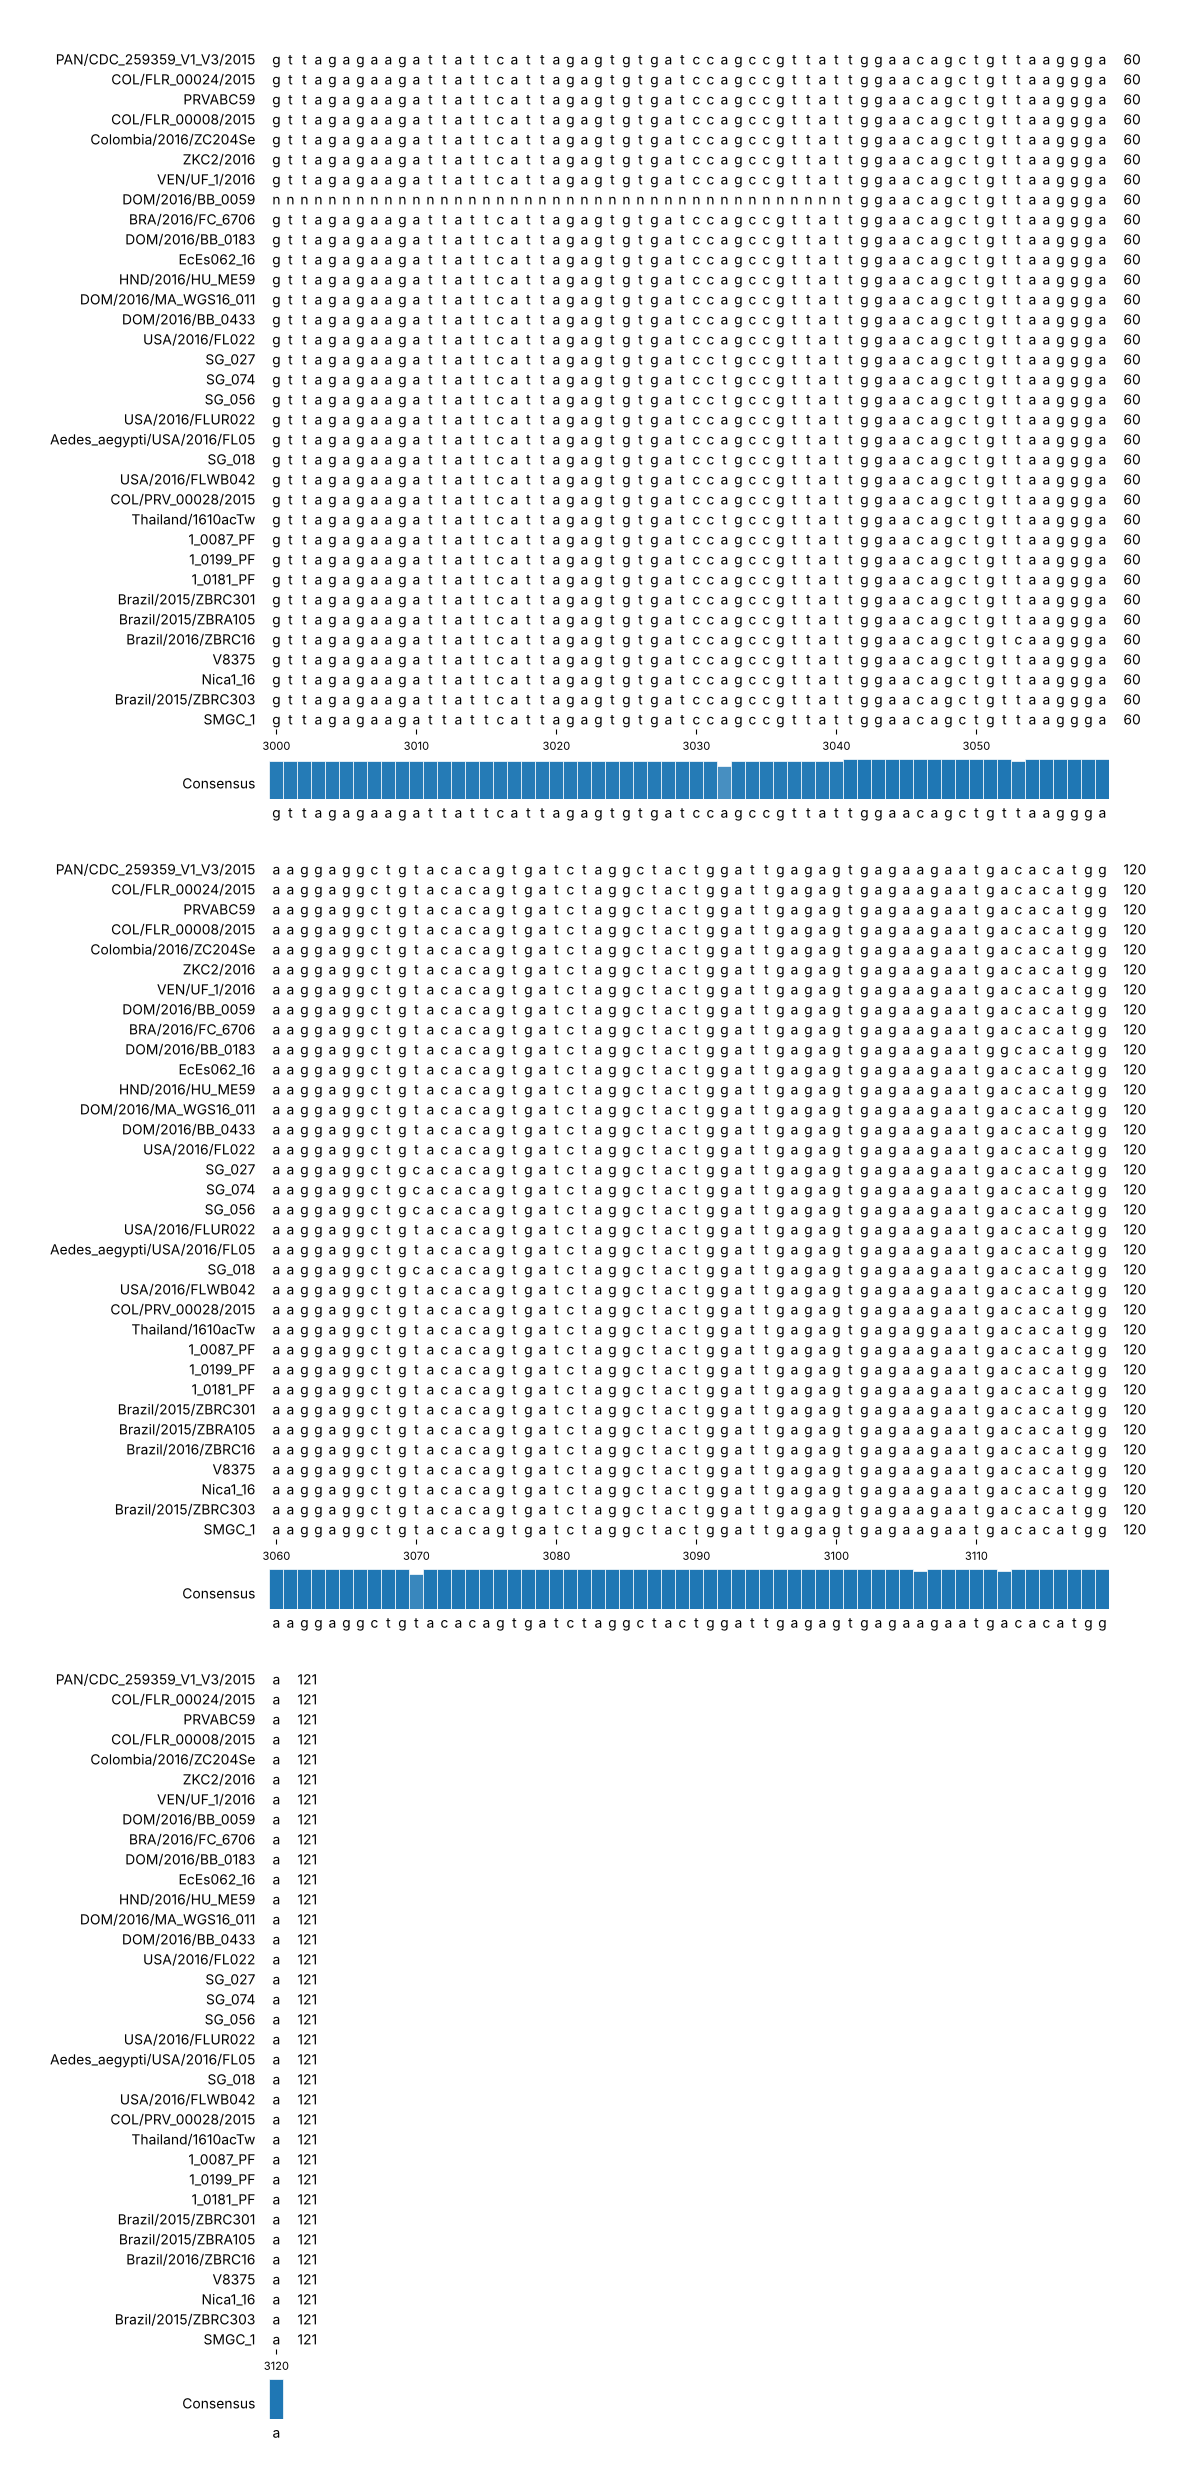

In [7]:
# Visualiza um trecho do alinhamento (colunas 3000–3120) para "ver" a conservação.
from pymsaviz import MsaViz

mv = MsaViz("zika_aln.fasta", start=3000, end=3120, wrap_length=60,
            show_consensus=True, show_count=True)
mv.savefig("alinhamento_trecho.png")
from IPython.display import Image
Image("alinhamento_trecho.png")

**O que observar:** colunas em que todos os genomas têm a mesma letra são **posições conservadas** (não variaram na evolução recente do vírus). As poucas colunas com letras diferentes são os **sítios variáveis** — são **essas** que carregam o sinal filogenético, isto é, a informação de parentesco. Um genoma viral recente como o do Zika é quase todo conservado; a árvore será construída a partir de um número relativamente pequeno de posições que diferem.

---
# Bloco C — A árvore de máxima verossimilhança com IQ-TREE (35 min)

Agora construímos a **árvore filogenética**: o diagrama que representa a hipótese de parentesco evolutivo entre os genomas.

Vamos usar o método de **máxima verossimilhança (ML)**. A ideia, em uma frase:

> dado um **modelo** de como os nucleotídeos mudam ao longo do tempo, a verossimilhança mede *o quão provável é observar as sequências que temos* para uma dada árvore (topologia + comprimentos de ramo). O ML procura a árvore que **maximiza** essa probabilidade.

Dois ingredientes precisam de atenção:

1. **O modelo de substituição.** Nem toda mudança de letra é igualmente provável: trocas entre bases quimicamente parecidas (transições, A↔G e C↔T) são muito mais comuns que transversões. O **ModelFinder** (embutido no IQ-TREE, acionado com `-m MFP`) testa dezenas de modelos e escolhe o melhor pelo critério **BIC**.
2. **O suporte dos ramos.** Uma árvore sempre sai — mas *quão confiável* é cada agrupamento? O **bootstrap ultrarrápido** (`-B 1000`) reconstrói a árvore 1000 vezes reamostrando as colunas e conta em quantas réplicas cada agrupamento reaparece. Valores **≥ 95%** indicam um ramo bem sustentado.

> **Reprodutibilidade:** fixamos `--seed 42`. Métodos com reamostragem aleatória dão resultados ligeiramente diferentes a cada execução; a semente torna o seu resultado repetível por outra pessoa — algo que o avaliador do artigo final vai cobrar.

In [8]:
# Roda o IQ-TREE: seleção de modelo (MFP) + 1000 réplicas de bootstrap ultrarrápido.
# Em 34 genomas, leva ~10-30 s.
import subprocess, time, os

for ext in [".iqtree", ".treefile", ".ckp.gz", ".log", ".bionj", ".mldist"]:
    f = "zika" + ext
    if os.path.exists(f):
        os.remove(f)

t0 = time.time()
subprocess.run([IQTREE, "-s", "zika_aln.fasta", "-m", "MFP",
                "-B", "1000", "-T", "2", "--seed", "42", "--prefix", "zika"],
               check=True, capture_output=True, text=True)
print("IQ-TREE concluído em %.1f s" % (time.time() - t0))

IQ-TREE concluído em 8.0 s


In [9]:
# Extrai do relatório (.iqtree) as informações-chave, em vez de abrir o arquivo inteiro.
texto = open("zika.iqtree").read()
import re
for chave in ["Best-fit model according to BIC",
              "Log-likelihood of the tree",
              "Total tree length (sum of branch lengths)",
              "Number of parsimony informative sites"]:
    for linha in texto.splitlines():
        if chave in linha:
            print(linha.strip()); break

Best-fit model according to BIC: TN+F+I
Log-likelihood of the tree: -18092.0810 (s.e. 153.3309)
Total tree length (sum of branch lengths): 0.0386
Number of parsimony informative sites: 190


**O que observar:** o ModelFinder deve ter escolhido um modelo da família **TN+F+I** (Tamura–Nei, frequências de base empíricas `+F`, mais uma fração de sítios invariáveis `+I`). Esse "+I" é a tradução estatística do que vimos no Bloco B: a maior parte das colunas **não varia**. O modelo não é um detalhe burocrático — usar um modelo pobre distorce os comprimentos de ramo e, portanto, as datas que estimaremos no Bloco E.

---
# Bloco D — Lendo e enraizando a árvore (20 min)

A árvore que o IQ-TREE produziu é **não enraizada**: ela mostra parentescos, mas não sabe por si só **onde está o passado**. Para lê-la como uma história no tempo, precisamos **enraizá-la**.

Usaremos o **enraizamento por grupo externo (*outgroup*)**: colocamos a raiz no ramo que separa as cepas **mais antigas e geograficamente mais basais** (as do Sudeste Asiático, de 2013) do resto. Isso corresponde à hipótese biológica de que a linhagem asiática é ancestral da que se espalhou pela Oceania e Américas.

In [10]:
# Lê a árvore e desenha em ASCII (sem precisar de biblioteca gráfica).
from Bio import Phylo
import pandas as pd

meta = pd.read_csv("metadata.tsv", sep="\t").set_index("strain")
arvore = Phylo.read("zika.treefile", "newick")

# Enraíza usando as cepas do Sudeste Asiático como grupo externo
externo = [t for t in arvore.get_terminals()
           if meta.loc[t.name, "region"] == "Southeast Asia"]
arvore.root_with_outgroup(externo)
print("Grupo externo (raiz):", [t.name for t in externo])
print()
Phylo.draw_ascii(arvore)

Grupo externo (raiz): ['SG_027', 'SG_074', 'SG_056', 'SG_018', 'Thailand/1610acTw']

                                       ___ PAN/CDC_259359_V1_V3/2015
                                      |
                                     ,|   , COL/FLR_00024/2015
                                     ||   |
                                     ||___|_ COL/FLR_00008/2015
                                _____|    |
                               |     |    |___ VEN/UF_1/2016
                               |     |
                               |     |_ Colombia/2016/ZC204Se
                               |
                               | ____ BRA/2016/FC_6706
                              _||
                             | || Brazil/2015/ZBRC303
                             | |
                             | |___ Brazil/2015/ZBRC301
                             |
                             |           , PRVABC59
                             | __________|
                             ||       

**Como ler este desenho:**

- Cada **ponta (folha)** é um genoma; o nome traz país/ano.
- Os **nós internos** são ancestrais comuns hipotéticos (não observados).
- O comprimento horizontal dos ramos é proporcional ao **número de substituições** acumuladas.
- Cepas que se agrupam num mesmo ramo compartilham um ancestral comum mais recente — ou seja, são **evolutivamente mais próximas**.

**O que observar:** as cepas do **Sudeste Asiático** e da **Oceania** ficam na base (mais próximas da raiz), e **todas as cepas das Américas formam um único grande grupo (um clado)**. Isso é uma evidência forte de uma **introdução única** do vírus nas Américas, seguida de dispersão local — e não de várias entradas independentes.

In [11]:
# Verifica quantitativamente: as cepas das Américas formam mesmo UM clado? Com que suporte?
americas = [t for t in arvore.get_terminals()
            if meta.loc[t.name, "region"] in ("South America", "North America")]
ancestral = arvore.common_ancestor(americas)

n_sob_ancestral = ancestral.count_terminals()
print("Cepas das Américas no conjunto :", len(americas))
print("Folhas sob o ancestral comum   :", n_sob_ancestral)
print("Formam um clado exclusivo?     :", n_sob_ancestral == len(americas))
print("Suporte (bootstrap) desse clado:", ancestral.confidence, "%")

Cepas das Américas no conjunto : 24
Folhas sob o ancestral comum   : 24
Formam um clado exclusivo?     : True
Suporte (bootstrap) desse clado: 93 %


**O que observar:** o ancestral comum das 24 cepas americanas contém **exatamente** essas 24 cepas (nenhuma intrusa), e o **bootstrap** desse agrupamento é alto (na faixa de ~90%). Em termos do artigo final, você escreveria algo como: *"as cepas americanas formaram um clado monofilético bem sustentado (UFBoot ≈ 92%), compatível com uma introdução única do vírus no continente"*. **Monofilético** = todos os descendentes de um mesmo ancestral, e só eles.

> **Cuidado com bootstrap:** suporte alto significa que **os dados são consistentes** com aquele agrupamento — não que ele seja uma verdade biológica absoluta. Com poucas posições variáveis, ramos curtos no interior da árvore podem ter suporte baixo; isso é honesto e deve ser relatado, não escondido.

---
# Bloco E — Datando a árvore: o relógio molecular (TreeTime) (20 min)

Até aqui, os ramos estão em **substituições por sítio**. A pergunta "*desde quando o vírus circulava nas Américas?*" precisa de ramos em **anos**. A ponte entre as duas coisas é o **relógio molecular**:

> se as mutações se acumulam a uma taxa aproximadamente constante no tempo, então **quanto mais recente** foi coletada uma amostra, **mais substituições** ela acumulou desde a raiz. A inclinação dessa relação é a **taxa de evolução** (substituições por sítio por ano).

O **TreeTime** faz duas coisas:
1. Testa se os dados são "relojoáveis" com a **regressão raiz-às-pontas** (*root-to-tip*): distância à raiz × data de coleta. Um **R²** razoável indica sinal temporal.
2. Converte a árvore de ML numa **árvore datada**, estimando a data de cada nó interno — inclusive o **ancestral comum das cepas americanas**, que é a resposta da nossa pergunta.

In [12]:
# Prepara o arquivo de datas (nome<TAB>data) que o TreeTime espera.
import pandas as pd
meta = pd.read_csv("metadata.tsv", sep="\t")
meta[["strain", "date"]].to_csv("datas.tsv", sep="\t", index=False,
                                header=["name", "date"])
print(open("datas.tsv").read()[:300], "...")

name	date
1_0087_PF	2013-12-XX
1_0181_PF	2013-12-XX
1_0199_PF	2013-11-XX
Aedes_aegypti/USA/2016/FL05	2016-09-09
BRA/2016/FC_6706	2016-04-08
Brazil/2015/ZBRA105	2015-02-23
Brazil/2015/ZBRC301	2015-05-13
Brazil/2015/ZBRC303	2015-05-14
Brazil/2016/ZBRC16	2016-01-19
COL/FLR_00008/2015	2015-12-XX
COL/FLR ...


In [13]:
# Ajusta o relógio molecular com a API do TreeTime (seed fixa p/ reprodutibilidade).
import numpy as np
from treetime import TreeTime
from treetime.utils import parse_dates
np.random.seed(42)

datas = parse_dates("datas.tsv")
tt = TreeTime(tree="zika.treefile", aln="zika_aln.fasta",
              dates=datas, verbose=1)
tt.run(root="least-squares", infer_gtr=True, max_iter=2,
       branch_length_mode="auto", time_marginal="assign",
       resolve_polytomies=True)

taxa = tt.clock_model["slope"]
r2 = tt.clock_model["r_val"] ** 2
print("\n--- Relógio molecular ---")
print("Taxa de evolução: %.2e substituições/sítio/ano" % taxa)
print("R² (sinal temporal): %.2f" % r2)


Attempting to parse dates...
	Using column 'name' as name. This needs match the taxon names in the tree!!
	Using column 'date' as date.



0.42	TreeTime.reroot: with method or node: least-squares

0.42	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

0.60	###TreeTime.run: INITIAL ROUND



2.61	TreeTime.reroot: with method or node: least-squares

2.61	TreeTime.reroot: rerooting will ignore covariance and shared ancestry.

2.65	###TreeTime.run: rerunning timetree after rerooting



4.69	###TreeTime.run: ITERATION 1 out of 2 iterations

4.69	DEPRECATION WARNING. TreeTime.resolve_polytomies: You are resolving
    	polytomies using the old 'greedy' mode. This is not well suited for large
    	polytomies. Stochastic resolution will become the default in future
    	versions. To switch now, rerun with the flag `--stochastic-resolve`. To
    	keep using the greedy method in the future, run with `--greedy-resolve`



6.95	###TreeTime.run: CONVERGED

6.95	###TreeTime.run: FINAL ROUND - confidence estimation via marginal
    	reconstruction



--- Relógio molecular ---
Taxa de evolução: 1.18e-03 substituições/sítio/ano
R² (sinal temporal): 0.79


**O que observar:** a taxa deve sair em torno de **~1 × 10⁻³ substituições por sítio por ano** — o valor típico relatado para o Zika e, de modo geral, para vírus de RNA (que evoluem rápido). O **R²** (~0,7) indica que uma boa parte da variação na distância à raiz é explicada pela data de coleta: há **sinal de relógio** suficiente para datar a árvore. Se o R² fosse próximo de zero, não poderíamos confiar nas datas — e isso também teria de ser dito no artigo.

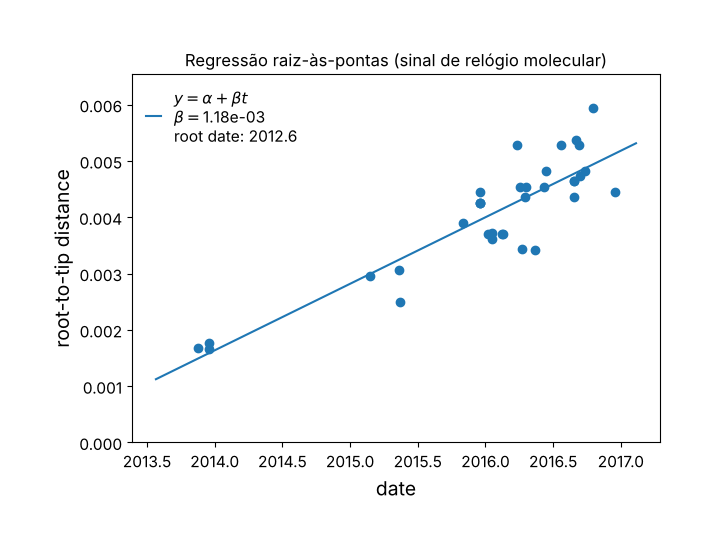

In [14]:
# Gráfico raiz-às-pontas: cada ponto é um genoma. A reta é o relógio.
import matplotlib.pyplot as plt
tt.plot_root_to_tip(add_internal=False)
plt.title("Regressão raiz-às-pontas (sinal de relógio molecular)")
plt.tight_layout(); plt.savefig("root_to_tip.png", dpi=120); plt.show()

**O que observar:** os pontos sobem da esquerda para a direita — amostras mais recentes (eixo x) estão mais distantes da raiz (eixo y). É essa inclinação positiva que autoriza a datação. Pontos muito fora da reta seriam candidatos a *outliers* (erro de data, contaminação, recombinação) e mereceriam investigação.

In [15]:
# Estima a data do ancestral comum das cepas das Américas, com intervalo de confiança.
meta_idx = pd.read_csv("metadata.tsv", sep="\t").set_index("strain")
americas = [t for t in tt.tree.get_terminals()
            if meta_idx.loc[t.name, "region"] in ("South America", "North America")]
mrca = tt.tree.common_ancestor(americas)

ic = tt.get_max_posterior_region(mrca, 0.95)
raiz = tt.tree.root
ic_raiz = tt.get_max_posterior_region(raiz, 0.95)

def ano_para_data(a):
    import datetime as dt
    ano = int(a); resto = a - ano
    return (dt.date(ano, 1, 1) + dt.timedelta(days=resto * 365.25)).isoformat()

print("ANCESTRAL COMUM DAS CEPAS AMERICANAS")
print("  Estimativa : %.2f  (%s)" % (mrca.numdate, ano_para_data(mrca.numdate)))
print("  IC 95%%     : %.2f – %.2f" % (ic[0], ic[1]))
print()
print("RAIZ DA ÁRVORE (linhagem ancestral amostrada)")
print("  Estimativa : %.2f  (IC 95%%: %.2f – %.2f)" % (raiz.numdate, ic_raiz[0], ic_raiz[1]))

ANCESTRAL COMUM DAS CEPAS AMERICANAS
  Estimativa : 2014.37  (2014-05-16)
  IC 95%     : 2014.15 – 2014.58

RAIZ DA ÁRVORE (linhagem ancestral amostrada)
  Estimativa : 2012.26  (IC 95%: 2011.65 – 2012.75)


**A resposta da prática.** O ancestral comum de todas as cepas americanas é datado de aproximadamente **meados de 2014** (a estimativa central cai por volta de maio de 2014, com intervalo de confiança de 95% em torno do primeiro semestre de 2014) — **mais de um ano antes** de a epidemia ser oficialmente reconhecida no Brasil, em 2015, e antes do pico de casos de 2015–2016.

Esta é exatamente a conclusão dos estudos publicados sobre a introdução do Zika nas Américas: **o vírus circulou de forma críptica (não detectada) por cerca de um ano** antes de ser notado. A combinação de **genomas + datas + filogenética** conseguiu enxergar uma circulação que a vigilância epidemiológica tradicional não viu em tempo real.

> **Honestidade metodológica:** 34 genomas são uma amostra pequena; o intervalo de confiança é largo e as datas dos nós dependem do modelo e do enraizamento. A mensagem robusta não é a data exata, e sim a **ordem de grandeza**: circulação silenciosa de ~1 ano. Reportar o intervalo de confiança — e não só o número central — é parte da análise.

In [16]:
# Salva a árvore datada para você usar/visualizar depois (ex.: no FigTree ou no iTOL).
from Bio import Phylo
Phylo.write(tt.tree, "zika_datada.nexus", "nexus")
print("Árvore datada salva em: zika_datada.nexus")
print("Dica: abra em https://itol.embl.de (iTOL) ou no FigTree para uma figura de artigo.")

Árvore datada salva em: zika_datada.nexus
Dica: abra em https://itol.embl.de (iTOL) ou no FigTree para uma figura de artigo.


---
# Fechamento — da prática de volta à teoria

Refizemos, do começo ao fim, um estudo real de **epidemiologia molecular**:

| Etapa | Conceito teórico | O que você viu na tela |
|---|---|---|
| A | Homologia posicional | Genomas de comprimentos diferentes — não dá para comparar sem alinhar |
| B | Alinhamento múltiplo (MSA) | 34×~10.800 colunas; quase tudo conservado, poucos sítios variáveis |
| C | Máxima verossimilhança + modelo de substituição | ModelFinder escolheu TN+F+I; viés transição/transversão |
| C | Suporte de ramo | Bootstrap ultrarrápido (UFBoot), ≥95% = ramo confiável |
| D | Enraizamento e monofilia | Clado americano único e bem sustentado → introdução única |
| E | Relógio molecular | Taxa ~10⁻³ subst./sítio/ano; R² mostra sinal temporal |
| E | Datação de nós (tMRCA) | Ancestral americano em ~meados de 2014: circulação silenciosa |

### Exercícios (para entregar)

1. **(Obrigatório)** Rode o IQ-TREE novamente trocando apenas a semente (`--seed 7` e `--seed 100`). O modelo escolhido muda? O suporte do clado americano muda muito? O que isso diz sobre reportar um único valor de bootstrap?
2. **(Obrigatório)** No Bloco D, troque o grupo externo: enraíze pela cepa mais antiga da Polinésia Francesa (`1_0087_PF`). A data estimada do ancestral americano muda? Discuta como a **escolha da raiz** afeta todas as datas.
3. **(Obrigatório)** Refaça a regressão raiz-às-pontas removendo as 5 cepas mais recentes. O R² melhora ou piora? Por quê?
4. **(Desafio)** Pegue uma proteína/gene da **sua linha de pesquisa**, baixe de 8 a 15 sequências homólogas do GenBank (use o que aprendeu na Aula 2 com BLAST), e refaça todo este pipeline (MAFFT → IQ-TREE → árvore enraizada). Entregue a figura da árvore com os suportes e um parágrafo interpretando os clados.

### Ferramentas usadas (todas livres / código aberto)

- **MAFFT** — https://mafft.cbrc.jp/alignment/software/
- **IQ-TREE 2** — http://www.iqtree.org
- **Biopython** — https://biopython.org
- **TreeTime** — https://github.com/neherlab/treetime
- **pyMSAviz** — https://github.com/moshi4/pyMSAviz
- Dados: tutorial público **Nextstrain/zika** — https://github.com/nextstrain/zika-tutorial

*Material da disciplina Introdução à Bioinformática — PPGED/IME. Todas as células foram executadas e verificadas antes da aula.*